# Clasificador Iris con PyTorch

**Data Science III — Checkpoint 1 | Pipeline de entrenamiento y validación**

**Objetivo:** entrenar un clasificador multiclase de las tres especies Iris mediante una red neuronal sencilla (`4 → 8 → 3`), documentar el aprendizaje y evaluar el resultado con flores reservadas para validación.

Este notebook es una versión **corregida y organizada** del ejercicio desarrollado durante las clases: mantiene el dataset Iris, la separación 80/20, la arquitectura, Adam y `learning_rate = 0.1` del archivo original. Añade reproducibilidad, comprobaciones, seguimiento coherente de métricas y recuperación de los mejores pesos.

> **Cómo usarlo:** ejecutar **Restart Kernel & Run All**. No necesita descargar un CSV: Iris viene incluido en `scikit-learn`. Los números y gráficos se recalculan en cada ejecución.


## 1. Entorno y configuración

Importamos las bibliotecas, establecemos una semilla y seleccionamos automáticamente **CUDA → MPS → CPU**. El modelo y los cuatro tensores se enviarán al mismo dispositivo. Esto evita incompatibilidades entre CPU y GPU.

**Reproducibilidad:** se fijan las semillas de NumPy y PyTorch. Los resultados de este ejercicio son reproducibles en el mismo entorno; diferentes versiones de bibliotecas o hardware GPU pueden presentar pequeñas variaciones.


In [1]:
import random
from copy import deepcopy

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import torch
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Semilla: {SEED} | Dispositivo: {device}")

PyTorch: 2.12.1+cpu
scikit-learn: 1.8.0
Matplotlib: 3.10.9
Semilla: 42 | Dispositivo: cpu


## 2. Dataset Iris: variables de entrada y objetivo

Iris reúne **150 flores** y cuatro medidas por flor: largo y ancho del sépalo, largo y ancho del pétalo. La variable `y` identifica una de tres especies (`0`, `1` o `2`).

**Recordatorio:** `(150, 4)` son **150 filas × 4 características**, no 4 flores. Las etiquetas tienen forma `(150,)`.


In [2]:
# Iris está integrado en scikit-learn: no requiere un archivo externo.
iris = load_iris()
X = iris.data  # Entradas: cuatro medidas en centímetros por flor.
y = iris.target  # Objetivo: clase entera 0, 1 o 2.

print("Características:", list(iris.feature_names))
print("Especies:", list(iris.target_names))
print("X.shape:", X.shape, "| y.shape:", y.shape)
print("Primer ejemplo:", X[0], "| Especie real:", y[0])

Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Especies: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
X.shape: (150, 4) | y.shape: (150,)
Primer ejemplo: [5.1 3.5 1.4 0.2] | Especie real: 0


## 3. Separación entrenamiento / validación

Reservamos el **20 %** (30 flores) para validación y el **80 %** (120 flores) para entrenamiento. `stratify=y` conserva las proporciones de las tres especies; `random_state=42` repite la misma partición.

**Regla de calidad:** no entrenar ni actualizar los pesos con `X_val`/`y_val`. Este notebook usa la validación para supervisar el entrenamiento y seleccionar el mejor estado, pero **no dispone de un conjunto de test independiente**; por tanto, las métricas de validación no representan una estimación final imparcial de desempeño externo.


In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("Clases entrenamiento:", np.bincount(y_train))
print("Clases validación:", np.bincount(y_val))

assert X_train.shape == (120, 4) and X_val.shape == (30, 4)
assert y_train.shape == (120,) and y_val.shape == (30,)

X_train: (120, 4) | y_train: (120,)
X_val:   (30, 4) | y_val:   (30,)
Clases entrenamiento: [40 40 40]
Clases validación: [10 10 10]


## 4. Tensores y tipos de datos

- `X_train_tensor` y `X_val_tensor`: **`float32`**, compatible con los pesos de la red.
- `y_train_tensor` y `y_val_tensor`: **`int64` (`torch.long`)**, índices enteros que necesita `CrossEntropyLoss`.

El método `.to(device)` garantiza que datos y red se ubiquen en el mismo dispositivo.


In [4]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).to(device)

assert X_train_tensor.shape == (120, 4)
assert X_val_tensor.shape == (30, 4)
assert X_train_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.long
assert X_train_tensor.device == y_train_tensor.device == device

print("X_train:", X_train_tensor.dtype, X_train_tensor.device)
print("y_train:", y_train_tensor.dtype, y_train_tensor.device)

X_train: torch.float32 cpu
y_train: torch.int64 cpu


## 5. Arquitectura: `4 → 8 → 3`

El clasificador tiene cuatro entradas, una capa oculta de ocho neuronas con activación `ReLU`, y tres salidas (una por especie). Las salidas finales son **logits**, no probabilidades: `CrossEntropyLoss` aplica internamente la operación apropiada; **no añadimos `Softmax`** antes de calcular el Loss.

Fijamos nuevamente la semilla justo antes de construir el modelo, para que la inicialización sea predecible aunque se inspeccionen celdas anteriores de forma interactiva.


In [5]:
torch.manual_seed(SEED)

modelo_iris = torch.nn.Sequential(
    torch.nn.Linear(4, 8),  # Cuatro características -> ocho neuronas ocultas.
    torch.nn.ReLU(),  # Introduce no linealidad.
    torch.nn.Linear(8, 3),  # Ocho activaciones -> tres logits (especies).
).to(device)

print(modelo_iris)
with torch.no_grad():
    salida_inicial = modelo_iris(X_train_tensor)

print("Forma de la salida:", tuple(salida_inicial.shape))
assert salida_inicial.shape == (120, 3)

Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=3, bias=True)
)
Forma de la salida: (120, 3)


### Interpretación: predicción y Accuracy inicial

`torch.argmax(..., dim=1)` devuelve el índice de la especie con el logit más alto **para cada flor**. Comparar con `y_train_tensor` produce `True` o `False`. Transformarlos a `float` y promediarlos da el Accuracy, una proporción entre 0 y 1.

Esta inspección se realiza **antes de entrenar**; sus valores dependen de los pesos iniciales y no se consideran desempeño final.


In [6]:
with torch.no_grad():
    predicciones_iniciales = salida_inicial.argmax(dim=1)
    accuracy_inicial = (predicciones_iniciales == y_train_tensor).float().mean().item()

print("Primeras 10 predicciones:", predicciones_iniciales[:10].tolist())
print("Primeras 10 etiquetas reales:", y_train_tensor[:10].tolist())
print(f"Accuracy inicial de entrenamiento: {accuracy_inicial * 100:.2f}%")

Primeras 10 predicciones: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Primeras 10 etiquetas reales: [0, 2, 1, 0, 1, 2, 1, 2, 2, 2]
Accuracy inicial de entrenamiento: 33.33%


## 6. Función de pérdida, Adam e hiperparámetros

- `CrossEntropyLoss()`: pérdida apropiada para **tres clases exclusivas**. Recibe logits de forma `(n, 3)` y etiquetas `long` de forma `(n,)`.
- `Adam`: optimizador que actualiza pesos y bias usando los gradientes.
- `learning_rate = 0.1`: valor del **notebook original**. Lo conservamos para respetar el experimento; en estudios posteriores conviene compararlo con otros valores.
- `patience = 10`: Early Stopping tolera diez épocas consecutivas sin una mejora del Loss de validación.

El optimizador se crea **después** de crear el modelo y moverlo al dispositivo.


In [7]:
LEARNING_RATE = 0.1
MAX_EPOCHS = 100
PATIENCE = 10

criterio_iris = torch.nn.CrossEntropyLoss()
optimizer_iris = torch.optim.Adam(modelo_iris.parameters(), lr=LEARNING_RATE)

print(f"lr={LEARNING_RATE} | max_epochs={MAX_EPOCHS} | patience={PATIENCE}")

lr=0.1 | max_epochs=100 | patience=10


### Función de evaluación

Calcula la pérdida y el accuracy del conjunto recibido, en modo
evaluación y sin registrar gradientes. Se utiliza tanto para
entrenamiento como para validación, sin actualizar los pesos.


In [8]:
def evaluar_modelo(modelo, entradas, etiquetas, criterio):
    modelo.eval()

    with torch.no_grad():
        logits = modelo(entradas)

        perdida = criterio(logits, etiquetas).item()

        predicciones = logits.argmax(dim=1)

        accuracy = (predicciones == etiquetas).float().mean().item()

    return perdida, accuracy

## 7. Entrenamiento, validación y Early Stopping

**En cada época** hacemos lo siguiente:

1. `train()`: activamos el modo entrenamiento, calculamos los logits y el Loss, limpiamos gradientes con `zero_grad()`, calculamos gradientes con `backward()` y actualizamos pesos con `step()`.
2. `eval()` y `no_grad()`: evaluamos **después del ajuste** tanto entrenamiento como validación con los mismos pesos actuales. Así ambas curvas resultan comparables.
3. Registramos **Loss y Accuracy** de ambos conjuntos en cuatro listas.
4. Si mejora el Loss de validación, guardamos una **copia independiente de los mejores pesos**. Si transcurren diez épocas seguidas sin mejora, `break` corta el bucle.
5. Al terminar, recuperamos los pesos de la mejor época, aunque esa no haya sido la última.

> Diferencia frente al archivo original: allí los pesos podían quedar en la última época aun si el mejor Loss de validación había ocurrido antes. Aquí conservamos y restauramos el mejor estado.


In [ ]:
# Historiales: se crean una sola vez, ANTES del for.
train_losses_iris = []
val_losses_iris = []
train_accuracies_iris = []
val_accuracies_iris = []

mejor_loss_val = float("inf")
mejor_epoca = -1
mejores_pesos = None
contador_paciencia = 0

early_stopping_activado = False

for epoch in range(MAX_EPOCHS):
    # 1) ENTRENAMIENTO: ajustar pesos exclusivamente con las 120 flores de train.
    modelo_iris.train()
    optimizer_iris.zero_grad()  # Evita acumular gradientes de la época anterior.
    salida_train = modelo_iris(X_train_tensor)  # Forward pass.
    loss = criterio_iris(salida_train, y_train_tensor)
    loss.backward()  # Autograd calcula los gradientes.
    optimizer_iris.step()  # Adam actualiza los parámetros.

    # 2) Evaluar ambos conjuntos después de actualizar los pesos.
    loss_train_epoca, accuracy_train_epoca = evaluar_modelo(
        modelo_iris, X_train_tensor, y_train_tensor, criterio_iris
    )

    loss_val_epoca, accuracy_val_epoca = evaluar_modelo(
        modelo_iris, X_val_tensor, y_val_tensor, criterio_iris
    )

    # 3) TRACKING: una medición por época, en el mismo orden.
    train_losses_iris.append(loss_train_epoca)
    val_losses_iris.append(loss_val_epoca)
    train_accuracies_iris.append(accuracy_train_epoca)
    val_accuracies_iris.append(accuracy_val_epoca)

    # 4) EARLY STOPPING: observar exclusivamente la pérdida de validación.
    if loss_val_epoca < mejor_loss_val:
        mejor_loss_val = loss_val_epoca
        mejor_epoca = epoch
        mejores_pesos = deepcopy(modelo_iris.state_dict())
        contador_paciencia = 0
    else:
        contador_paciencia += 1

    if contador_paciencia >= PATIENCE:
        early_stopping_activado = True
        break

# 5) Reponer el modelo que consiguió el menor Loss de validación.
assert mejores_pesos is not None
modelo_iris.load_state_dict(mejores_pesos)
modelo_iris.eval()

Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=3, bias=True)
)

In [10]:
perdida_val, accuracy_val = evaluar_modelo(
    modelo_iris, X_val_tensor, y_val_tensor, criterio_iris
)

print(f"Pérdida de validación: {perdida_val:.6f}")
print(f"Accuracy de validación: {accuracy_val:.2%}")


Pérdida de validación: 0.177231
Accuracy de validación: 96.67%


## 8. Comprobaciones del ciclo

Las cuatro listas deben tener **exactamente tantas entradas como épocas realmente ejecutadas**. Si Early Stopping actúa, esa cantidad será menor que `MAX_EPOCHS`. Un mínimo en el índice `99` corresponde a la **época 100** (Python empieza en cero).


In [11]:
epocas_ejecutadas = len(train_losses_iris)
assert epocas_ejecutadas == len(val_losses_iris)
assert epocas_ejecutadas == len(train_accuracies_iris)
assert epocas_ejecutadas == len(val_accuracies_iris)
assert 1 <= epocas_ejecutadas <= MAX_EPOCHS
assert mejor_epoca == int(np.argmin(val_losses_iris))

print(f"Épocas ejecutadas: {epocas_ejecutadas} / {MAX_EPOCHS}")
print(f"Mejor época: {mejor_epoca + 1} (índice {mejor_epoca})")
print(f"Mejor Loss de validación: {mejor_loss_val:.6f}")
print("Early Stopping:", "ACTIVADO" if early_stopping_activado else "NO ACTIVADO")

Épocas ejecutadas: 100 / 100
Mejor época: 100 (índice 99)
Mejor Loss de validación: 0.177231
Early Stopping: NO ACTIVADO


## 9. Evaluación del mejor modelo

Evaluamos los pesos recuperados tras el entrenamiento. **La validación no actualiza el modelo**. Para un informe final que estime el rendimiento fuera de este experimento debería reservarse además un test independiente.


In [12]:
modelo_iris.eval()
with torch.no_grad():
    logits_train_final = modelo_iris(X_train_tensor)
    logits_val_final = modelo_iris(X_val_tensor)

    loss_train_final = criterio_iris(logits_train_final, y_train_tensor).item()
    loss_val_final = criterio_iris(logits_val_final, y_val_tensor).item()

    predicciones_train = logits_train_final.argmax(dim=1)
    predicciones_val = logits_val_final.argmax(dim=1)

    accuracy_train_final = (predicciones_train == y_train_tensor).float().mean().item()
    accuracy_val_final = (predicciones_val == y_val_tensor).float().mean().item()
    aciertos_val_final = int((predicciones_val == y_val_tensor).sum().item())

assert abs(loss_val_final - mejor_loss_val) < 1e-5

print(f"Loss entrenamiento (mejor modelo): {loss_train_final:.6f}")
print(f"Loss validación (mejor modelo):   {loss_val_final:.6f}")
print(f"Accuracy entrenamiento: {accuracy_train_final * 100:.2f}%")
print(f"Accuracy validación:    {accuracy_val_final * 100:.2f}%")
print(f"Aciertos validación: {aciertos_val_final} / {len(y_val)}")

Loss entrenamiento (mejor modelo): 0.154392
Loss validación (mejor modelo):   0.177231
Accuracy entrenamiento: 97.50%
Accuracy validación:    96.67%
Aciertos validación: 29 / 30


## 10. Visualizaciones

### 10.1 Curvas de Loss

**Eje X:** época. **Eje Y:** Loss (Cross Entropy). La línea vertical punteada indica la época donde se alcanzó el menor Loss de validación. Una curva de entrenamiento descendente no garantiza generalización: para eso comparamos con la curva de validación.


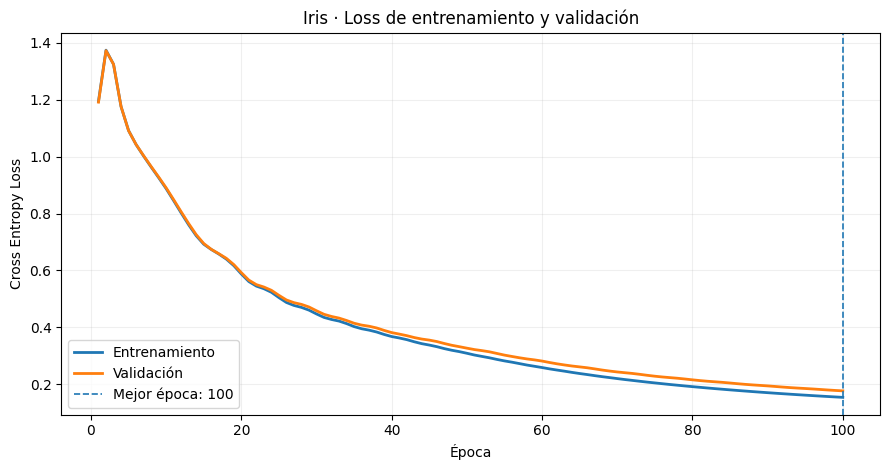

In [13]:
epocas = range(1, epocas_ejecutadas + 1)
plt.figure(figsize=(9, 4.8))
plt.plot(epocas, train_losses_iris, label="Entrenamiento", linewidth=2)
plt.plot(epocas, val_losses_iris, label="Validación", linewidth=2)
plt.axvline(
    mejor_epoca + 1,
    linestyle="--",
    linewidth=1.2,
    label=f"Mejor época: {mejor_epoca + 1}",
)
plt.title("Iris · Loss de entrenamiento y validación")
plt.xlabel("Época")
plt.ylabel("Cross Entropy Loss")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

### 10.2 Curvas de Accuracy

**Eje Y:** porcentaje de flores clasificadas correctamente. El Accuracy puede permanecer estable mientras el Loss continúa disminuyendo, porque el modelo sigue ajustando las puntuaciones aunque no cambien las clases predichas.


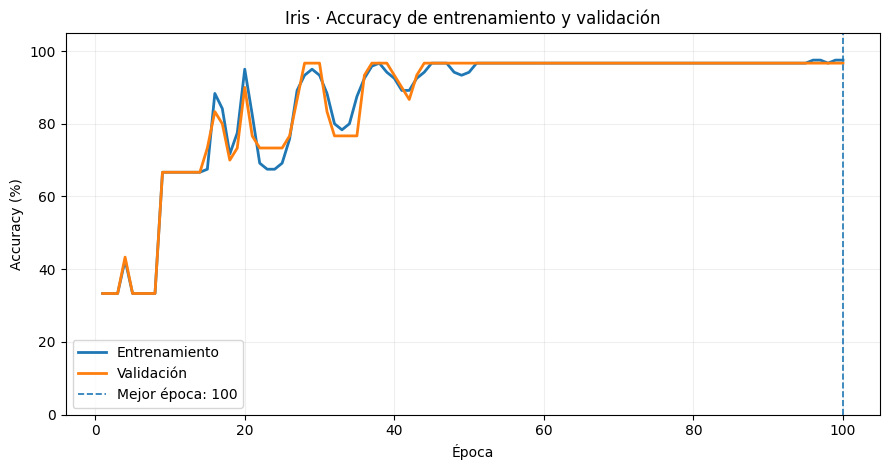

In [14]:
plt.figure(figsize=(9, 4.8))
plt.plot(
    epocas, np.array(train_accuracies_iris) * 100, label="Entrenamiento", linewidth=2
)
plt.plot(epocas, np.array(val_accuracies_iris) * 100, label="Validación", linewidth=2)
plt.axvline(
    mejor_epoca + 1,
    linestyle="--",
    linewidth=1.2,
    label=f"Mejor época: {mejor_epoca + 1}",
)
plt.title("Iris · Accuracy de entrenamiento y validación")
plt.xlabel("Época")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Interpretación de resultados

La celda siguiente crea un resumen reproducible a partir de **los valores reales de esta ejecución** (no de datos copiados manualmente). Para la entrega, relacioná la evolución del Loss y el Accuracy de validación con las figuras anteriores.


In [15]:
print("RESUMEN DEL EXPERIMENTO")
print("- Dataset: Iris (150 flores, 4 características, 3 especies)")
print("- División: 120 train / 30 validación, estratificada (seed 42)")
print("- Red: 4 → 8 (ReLU) → 3 | Optimizador: Adam")
print(f"- Dispositivo: {device} | Learning rate: {LEARNING_RATE}")
print(f"- Épocas ejecutadas: {epocas_ejecutadas} | Mejor época: {mejor_epoca + 1}")
print(f"- Mejor Loss de validación: {mejor_loss_val:.4f}")
print(f"- Accuracy validación del mejor modelo: {accuracy_val_final * 100:.2f}%")
if early_stopping_activado:
    print(f"- Early Stopping: activado (patience={PATIENCE})")
else:
    print("- Early Stopping: no activado; se completó el máximo de épocas")
print("- Límite: 30 flores de validación; no existe test independiente")

RESUMEN DEL EXPERIMENTO
- Dataset: Iris (150 flores, 4 características, 3 especies)
- División: 120 train / 30 validación, estratificada (seed 42)
- Red: 4 → 8 (ReLU) → 3 | Optimizador: Adam
- Dispositivo: cpu | Learning rate: 0.1
- Épocas ejecutadas: 100 | Mejor época: 100
- Mejor Loss de validación: 0.1772
- Accuracy validación del mejor modelo: 96.67%
- Early Stopping: no activado; se completó el máximo de épocas
- Límite: 30 flores de validación; no existe test independiente


## 12. Notas metodológicas y próximos pasos

**Qué se corrigió respecto del notebook original**

1. El dispositivo ahora se selecciona **antes** del modelo, de la transferencia de tensores y del optimizador (antes estaba al final).
2. Se respeta una ejecución ordenada sin repetir la creación del modelo ni reutilizar parámetros entrenados.
3. Se documentan `float32` para `X`, `long` para `y` y el uso de logits en `CrossEntropyLoss`.
4. Las métricas de entrenamiento y validación se miden **después** de la actualización de pesos de cada época, para facilitar su comparación.
5. Early Stopping ahora conserva y restaura los **mejores pesos**; no solo detiene el `for`.
6. Se registra **Loss y Accuracy por época** tanto en entrenamiento como en validación.
7. Se reemplazan impresiones extensas de matrices por comprobaciones puntuales y gráficos legibles.

**Alcance y limitaciones:** esta es una prueba técnica de pipeline, no una validación definitiva del modelo. Iris es pequeño; 30 ejemplos de validación hacen que el Accuracy cambie 3,33 puntos porcentuales por cada flor adicional acertada. No se creó un conjunto de test independiente. Como próxima mejora, se puede ensayar escalado de características ajustado **solo con los datos de entrenamiento**, otro learning rate, y una partición adicional de test.

**Para GitHub:** adjuntar este notebook, `requirements.txt`, `README.md` y commits descriptivos. Ejecutar **Restart Kernel & Run All** antes de subir la versión final.
